In [ ]:
'''
Both WL and NBI imaging technologies are included
Metadata provided by the gastroenterologist
1. Number of polyps of interest found during the procedure;
2. Current polyp ID;
3. Polyp size, in millimetres;
4. Paris classification [26,27];
5. NICE classification [29];
6. Preliminary diagnosis
The pathologist completed the metadata:
1. Final diagnosis;
2. Histological stratification.

Video clips were processed to extract the individual frames.
All frames were analysed and categorized into showing a polyp or not, as well as identifying the type of light source (WL or NBI)
76 lesions from 40 patients
62 out of these 76 lesions included white light (WL) and narrow band imaging (NBI) frames, while the remaining 14 lesions are recorded only using WL

'''

In [1]:
import cv2
import pandas as pd
from PIL import Image, ImageDraw
import numpy as np
from scipy import ndimage as ndi
import tkinter as tk
from tkinter import filedialog
from datetime import datetime
import matplotlib.pyplot as plt
import os
from common import get_image_properties

In [2]:
# Open file dialog to select the spreadsheet file
csv_path = filedialog.askopenfilename(
    title="Select the csv file",
    filetypes=[("CSV files", "*.csv")]
)

In [3]:
# Attempting to read the CSV file with a different encoding, in case of encoding issues
try:
    piccolo_df = pd.read_csv(csv_path, encoding='ISO-8859-1', delimiter=';')
except Exception as e:
    print("Error reading file:", e)
piccolo_df

,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION,NICE,PRELIMINAR DIAGNOSIS (Gastroenterologist),LITERAL DIAGNOSIS (Pathologist),HISTOLOGICAL STRATIFICATION,Set,Unnamed: 11,Unnamed: 12
0,1.0,VP1,1.0,(1/1),3,Flat elevated lesions: 0-lla,Type 2,Adenoma,Adenoma,No dysplasia,Train,NaN,NaN
1,2.0,VP2,1.0,(1/1),5,Protruded lesions: Ip,Type 2,Adenoma,Adenoma,No dysplasia,Validation,NaN,NaN
2,3.0,VP3,1.0,(1/1),7,Protruded lesions: Ips,Type 2,Adenoma,Adenoma,No dysplasia,Test,NaN,NaN
3,4.0,VP4,2.0,(1/2),2,Flat elevated lesions:0-lla/c,Type 2,Adenoma,Adenoma,No dysplasia,Test,NaN,NaN
4,5.0,VP4,2.0,(2/2),3,Flat elevated lesions: 0-lla,Type 2,Adenoma,Adenoma,No dysplasia,Test,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
86,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
87,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Replacing "-" placeholder values with NaN
piccolo_df = piccolo_df.replace('-', pd.NA)
# Dropping rows where all elements are NaN
piccolo_df = piccolo_df.dropna(how='all')
# Dropping columns where all elements are NaN
piccolo_df = piccolo_df.dropna(axis=1, how='all')

piccolo_df

,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION,NICE,PRELIMINAR DIAGNOSIS (Gastroenterologist),LITERAL DIAGNOSIS (Pathologist),HISTOLOGICAL STRATIFICATION,Set
0,1.0,VP1,1.0,(1/1),3,Flat elevated lesions: 0-lla,Type 2,Adenoma,Adenoma,No dysplasia,Train
1,2.0,VP2,1.0,(1/1),5,Protruded lesions: Ip,Type 2,Adenoma,Adenoma,No dysplasia,Validation
2,3.0,VP3,1.0,(1/1),7,Protruded lesions: Ips,Type 2,Adenoma,Adenoma,No dysplasia,Test
3,4.0,VP4,2.0,(1/2),2,Flat elevated lesions:0-lla/c,Type 2,Adenoma,Adenoma,No dysplasia,Test
4,5.0,VP4,2.0,(2/2),3,Flat elevated lesions: 0-lla,Type 2,Adenoma,Adenoma,No dysplasia,Test
...,...,...,...,...,...,...,...,...,...,...,...
71,72.0,VP21,5.0,(1/5),3,Protruded lesions: Is,Type 2,Adenoma,Adenoma,No dysplasia,Train
72,73.0,VP21,5.0,(2/5),8,Protruded lesions: Is,Type 2,Adenoma,Adenoma,No dysplasia,Train
73,74.0,VP21,5.0,(3/5),6,Protruded lesions: Is,Type 2,Adenoma,Adenoma,No dysplasia,Train
74,75.0,VP21,5.0,(4/5),9,Protruded lesions: Ips,Type 2,Adenoma,Adenoma,No dysplasia,Train


In [5]:
columns_to_drop = ['HISTOLOGICAL STRATIFICATION', 'LITERAL DIAGNOSIS (Pathologist)', 
                             'PRELIMINAR DIAGNOSIS\xa0 (Gastroenterologist)', 'NICE ']

# Dropping the correctly named columns
piccolo_df = piccolo_df.drop(columns=columns_to_drop)

piccolo_df

,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION,Set
0,1.0,VP1,1.0,(1/1),3,Flat elevated lesions: 0-lla,Train
1,2.0,VP2,1.0,(1/1),5,Protruded lesions: Ip,Validation
2,3.0,VP3,1.0,(1/1),7,Protruded lesions: Ips,Test
3,4.0,VP4,2.0,(1/2),2,Flat elevated lesions:0-lla/c,Test
4,5.0,VP4,2.0,(2/2),3,Flat elevated lesions: 0-lla,Test
...,...,...,...,...,...,...,...
71,72.0,VP21,5.0,(1/5),3,Protruded lesions: Is,Train
72,73.0,VP21,5.0,(2/5),8,Protruded lesions: Is,Train
73,74.0,VP21,5.0,(3/5),6,Protruded lesions: Is,Train
74,75.0,VP21,5.0,(4/5),9,Protruded lesions: Ips,Train


In [6]:
# Code version formatting
# Handling NaN values before converting 'CODE - LESION' to a three-digit code format
piccolo_df['CODE - LESION'] = piccolo_df['CODE - LESION'].fillna(0).apply(lambda x: '{:03d}'.format(int(x)))
piccolo_df

,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION,Set
0,001,VP1,1.0,(1/1),3,Flat elevated lesions: 0-lla,Train
1,002,VP2,1.0,(1/1),5,Protruded lesions: Ip,Validation
2,003,VP3,1.0,(1/1),7,Protruded lesions: Ips,Test
3,004,VP4,2.0,(1/2),2,Flat elevated lesions:0-lla/c,Test
4,005,VP4,2.0,(2/2),3,Flat elevated lesions: 0-lla,Test
...,...,...,...,...,...,...,...
71,072,VP21,5.0,(1/5),3,Protruded lesions: Is,Train
72,073,VP21,5.0,(2/5),8,Protruded lesions: Is,Train
73,074,VP21,5.0,(3/5),6,Protruded lesions: Is,Train
74,075,VP21,5.0,(4/5),9,Protruded lesions: Ips,Train


In [7]:
# Converting 'NUMBER OF POLYPS OF INTEREST (N)' to an integer value
piccolo_df['NUMBER OF POLYPS OF INTEREST (N)'] = piccolo_df['NUMBER OF POLYPS OF INTEREST (N)'].fillna(0).astype(int)
piccolo_df

,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION,Set
0,001,VP1,1,(1/1),3,Flat elevated lesions: 0-lla,Train
1,002,VP2,1,(1/1),5,Protruded lesions: Ip,Validation
2,003,VP3,1,(1/1),7,Protruded lesions: Ips,Test
3,004,VP4,2,(1/2),2,Flat elevated lesions:0-lla/c,Test
4,005,VP4,2,(2/2),3,Flat elevated lesions: 0-lla,Test
...,...,...,...,...,...,...,...
71,072,VP21,5,(1/5),3,Protruded lesions: Is,Train
72,073,VP21,5,(2/5),8,Protruded lesions: Is,Train
73,074,VP21,5,(3/5),6,Protruded lesions: Is,Train
74,075,VP21,5,(4/5),9,Protruded lesions: Ips,Train


In [8]:
# Define the base path where the folders are located
base_path = os.path.dirname(csv_path)

# New DataFrame structure
new_frame_data = []

# Iterate through the 'test', 'train', and 'validation' folders
for set_name in ['test', 'train', 'validation']:
    mask_folder_path = os.path.join(base_path, set_name, 'polyps')
    
    # Check if the mask folder exists
    if os.path.exists(mask_folder_path) and os.path.isdir(mask_folder_path):
        # List all frame files in the directory
        for frame_file in os.listdir(mask_folder_path):
            if frame_file.endswith('.png'):
                code_lesion, code_video, _ = frame_file.split('_')
                matching_row = piccolo_df[(piccolo_df['CODE - LESION'] == code_lesion) & 
                                           (piccolo_df['CODE - VIDEO'] == code_video)]

                # If a matching row is found in the original dataframe
                if not matching_row.empty:
                    # Extract the row as a dictionary and add the frame file info
                    frame_data = {'FRAME': frame_file}
                    frame_data['SET'] = set_name
                    # Add other data from the matching row
                    for col in piccolo_df.columns[:-1]:
                        frame_data[col] = matching_row.iloc[0][col]
                    
                    new_frame_data.append(frame_data)

# Create the new DataFrame
extended_piccolo_df = pd.DataFrame(new_frame_data)

extended_piccolo_df

,FRAME,SET,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION
0,011_VP9_frame0071.png,test,011,VP9,2,(2/2),<NA>,<NA>
1,011_VP9_frame0515.png,test,011,VP9,2,(2/2),<NA>,<NA>
2,064_VP24_frame1582.png,test,064,VP24,1,(1/1),4,Flat lesions: 0-llb
3,012_VP9_frame0389.png,test,012,VP9,2,(2/2),<NA>,<NA>
4,010_VP9_frame0301.png,test,010,VP9,2,(1/2),7,Protruded lesions: Ip
...,...,...,...,...,...,...,...,...
3428,038_VP31_frame0679.png,validation,038,VP31,4,(4/4),10,Flat lesions: 0-llb
3429,047_VP36_frame0048.png,validation,047,VP36,1,(1/1),50,Protruded lesions: Is
3430,030_VP45_frame1117.png,validation,030,VP45,1,(1/1),<NA>,<NA>
3431,037_VP31_frame0101.png,validation,037,VP31,4,(3/4),15,Flat elevated lesions: 0-lla


In [9]:
extended_piccolo_df = extended_piccolo_df.dropna(subset=['PARIS CLASSIFICATION'])
extended_piccolo_df

,FRAME,SET,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION
2,064_VP24_frame1582.png,test,064,VP24,1,(1/1),4,Flat lesions: 0-llb
4,010_VP9_frame0301.png,test,010,VP9,2,(1/2),7,Protruded lesions: Ip
9,004_VP4_frame0793.png,test,004,VP4,2,(1/2),2,Flat elevated lesions:0-lla/c
10,005_VP4_frame0226.png,test,005,VP4,2,(2/2),3,Flat elevated lesions: 0-lla
11,064_VP24_frame0716.png,test,064,VP24,1,(1/1),4,Flat lesions: 0-llb
...,...,...,...,...,...,...,...,...
3426,037_VP31_frame0317.png,validation,037,VP31,4,(3/4),15,Flat elevated lesions: 0-lla
3428,038_VP31_frame0679.png,validation,038,VP31,4,(4/4),10,Flat lesions: 0-llb
3429,047_VP36_frame0048.png,validation,047,VP36,1,(1/1),50,Protruded lesions: Is
3431,037_VP31_frame0101.png,validation,037,VP31,4,(3/4),15,Flat elevated lesions: 0-lla


In [10]:
# Adding width and height columns to the DataFrame
extended_piccolo_df['WIDTH'] = None
extended_piccolo_df['HEIGHT'] = None

for index, row in extended_piccolo_df.iterrows():
    frame_path = os.path.join(base_path, row['SET'], 'polyps', row['FRAME'])
    try:
        with Image.open(frame_path) as img:
            width, height = img.size
            extended_piccolo_df.at[index, 'WIDTH'] = width
            extended_piccolo_df.at[index, 'HEIGHT'] = height
    except IOError:
        print(f"Unable to open file: {frame_path}")

extended_piccolo_df

/var/folders/09/7_lhn8c12k90ktfsdlxf2nsh0000gn/T/ipykernel_17549/3554599420.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  extended_piccolo_df['WIDTH'] = None
/var/folders/09/7_lhn8c12k90ktfsdlxf2nsh0000gn/T/ipykernel_17549/3554599420.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  extended_piccolo_df['HEIGHT'] = None


,FRAME,SET,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION,WIDTH,HEIGHT
2,064_VP24_frame1582.png,test,064,VP24,1,(1/1),4,Flat lesions: 0-llb,854,480
4,010_VP9_frame0301.png,test,010,VP9,2,(1/2),7,Protruded lesions: Ip,854,480
9,004_VP4_frame0793.png,test,004,VP4,2,(1/2),2,Flat elevated lesions:0-lla/c,854,480
10,005_VP4_frame0226.png,test,005,VP4,2,(2/2),3,Flat elevated lesions: 0-lla,854,480
11,064_VP24_frame0716.png,test,064,VP24,1,(1/1),4,Flat lesions: 0-llb,854,480
...,...,...,...,...,...,...,...,...,...,...
3426,037_VP31_frame0317.png,validation,037,VP31,4,(3/4),15,Flat elevated lesions: 0-lla,1920,1080
3428,038_VP31_frame0679.png,validation,038,VP31,4,(4/4),10,Flat lesions: 0-llb,1920,1080
3429,047_VP36_frame0048.png,validation,047,VP36,1,(1/1),50,Protruded lesions: Is,1920,1080
3431,037_VP31_frame0101.png,validation,037,VP31,4,(3/4),15,Flat elevated lesions: 0-lla,1920,1080


In [11]:
# Function to calculate the bounding box of a mask
def calculate_bounding_box(mask):
    # Find all non-zero points (where the mask is)
    rows = np.any(mask, axis=1)
    cols = np.any(mask, axis=0)
    ymin, ymax = np.where(rows)[0][[0, -1]]
    xmin, xmax = np.where(cols)[0][[0, -1]]

    # Check if the bounding box is at least 2x2 pixels
    if (ymax - ymin) > 1 and (xmax - xmin) > 1:
        return f"{xmin},{ymin},{xmax},{ymax}"
    else:
        return None


# Adding bounding box column to the DataFrame
extended_piccolo_df['BOUNDING BOX'] = None

for index, row in extended_piccolo_df.iterrows():
    mask_path = os.path.join(base_path, row['SET'], 'masks', row['FRAME'].replace('.png', '_Corrected.tif'))
    try:
        with Image.open(mask_path) as img:
            mask = np.array(img)
            
            # Assuming the mask is binary (0 or 255)
            mask = mask > 0
            
            # Calculate bounding box for each connected component (mask)
            bounding_boxes = []
            # Labeling connected components in the mask
            labeled, num_labels = ndi.label(mask)
            for label_num in range(1, num_labels + 1):
                label_mask = labeled == label_num
                bbox = calculate_bounding_box(label_mask)
                if bbox:
                    bounding_boxes.append(bbox)
            
            # Join all bounding box strings with a space
            extended_piccolo_df.at[index, 'BOUNDING BOX'] = ' '.join(bounding_boxes)
    except IOError:
        print(f"Unable to open file: {mask_path}")

extended_piccolo_df

/var/folders/09/7_lhn8c12k90ktfsdlxf2nsh0000gn/T/ipykernel_17549/3928327206.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  extended_piccolo_df['BOUNDING BOX'] = None


,FRAME,SET,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION,WIDTH,HEIGHT,BOUNDING BOX
2,064_VP24_frame1582.png,test,064,VP24,1,(1/1),4,Flat lesions: 0-llb,854,480,"500,120,638,255"
4,010_VP9_frame0301.png,test,010,VP9,2,(1/2),7,Protruded lesions: Ip,854,480,"209,190,471,479"
9,004_VP4_frame0793.png,test,004,VP4,2,(1/2),2,Flat elevated lesions:0-lla/c,854,480,"363,207,529,355"
10,005_VP4_frame0226.png,test,005,VP4,2,(2/2),3,Flat elevated lesions: 0-lla,854,480,"410,165,570,344"
11,064_VP24_frame0716.png,test,064,VP24,1,(1/1),4,Flat lesions: 0-llb,854,480,"403,141,495,203"
...,...,...,...,...,...,...,...,...,...,...,...
3426,037_VP31_frame0317.png,validation,037,VP31,4,(3/4),15,Flat elevated lesions: 0-lla,1920,1080,"380,330,1651,1079"
3428,038_VP31_frame0679.png,validation,038,VP31,4,(4/4),10,Flat lesions: 0-llb,1920,1080,"310,165,1339,1079"
3429,047_VP36_frame0048.png,validation,047,VP36,1,(1/1),50,Protruded lesions: Is,1920,1080,"309,0,1660,1079"
3431,037_VP31_frame0101.png,validation,037,VP31,4,(3/4),15,Flat elevated lesions: 0-lla,1920,1080,"825,384,1564,976"


In [12]:
entries_with_multiple_bboxes = extended_piccolo_df[extended_piccolo_df['BOUNDING BOX'].str.count(',') > 3]
entries_with_multiple_bboxes

,FRAME,SET,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION,WIDTH,HEIGHT,BOUNDING BOX
37,009_VP7_frame0213.png,test,009,VP7,1,(1/1),3,Protruded lesions: Is,854,480,"236,195,321,271 361,253,573,390"
65,009_VP7_frame0000.png,test,009,VP7,1,(1/1),3,Protruded lesions: Is,854,480,"182,199,280,300 318,257,633,479"
90,009_VP7_frame0064.png,test,009,VP7,1,(1/1),3,Protruded lesions: Is,854,480,"243,186,349,276 386,243,595,392"
181,009_VP7_frame0454.png,test,009,VP7,1,(1/1),3,Protruded lesions: Is,854,480,"213,243,310,335 359,328,568,453"
189,009_VP7_frame0285.png,test,009,VP7,1,(1/1),3,Protruded lesions: Is,854,480,"215,202,320,282 359,266,570,409"
...,...,...,...,...,...,...,...,...,...,...,...
3118,047_VP36_frame0606.png,validation,047,VP36,1,(1/1),50,Protruded lesions: Is,1920,1080,"423,0,1660,1079 484,272,487,282"
3136,047_VP36_frame0558.png,validation,047,VP36,1,(1/1),50,Protruded lesions: Is,1920,1080,"314,0,1660,1013 1459,716,1660,1028"
3283,059_VP17_frame3463.png,validation,059,VP17,2,(1/2),28,Flat elevated lesions: 0-lla,854,480,"432,2,440,12 406,299,595,430"
3377,037_VP31_frame0260.png,validation,037,VP31,4,(3/4),15,Flat elevated lesions: 0-lla,1920,1080,"881,257,1620,1001 1618,843,1624,856"


In [13]:
# Filtering out entries with no bounding box
extended_piccolo_df = extended_piccolo_df[extended_piccolo_df['BOUNDING BOX'] != '']

In [14]:
# Function to draw bounding boxes on an image
def draw_bounding_boxes(image_path, bounding_boxes, save_path):
    # Open the image
    with Image.open(image_path) as img:
        draw = ImageDraw.Draw(img)

        # Draw each bounding box
        for bbox_str in bounding_boxes.split(' '):
            coordinates = [int(coord.strip()) for coord in bbox_str.split(',') if coord.strip()]
            print(coordinates)
            draw.rectangle(coordinates, outline="red", width=2)
        
        # Display the image
        # plt.imshow(img)
        # plt.show()
        
        # Save the image with bounding boxes
        img.save(save_path)

save_base_path = os.path.join(base_path, 'img_bbox')

# Create the save directory if it doesn't exist
os.makedirs(save_base_path, exist_ok=True)

# Loop through the DataFrame and draw bounding boxes on each image
for index, row in extended_piccolo_df.iterrows():
    frame_path = os.path.join(base_path, row['SET'], 'polyps', row['FRAME'])
    save_path = os.path.join(save_base_path, f"bbox_{row['FRAME']}") 
    draw_bounding_boxes(frame_path, row['BOUNDING BOX'], save_path)


2 064_VP24_frame1582.png test
[500, 120, 638, 255]
4 010_VP9_frame0301.png test
[209, 190, 471, 479]
9 004_VP4_frame0793.png test
[363, 207, 529, 355]
10 005_VP4_frame0226.png test
[410, 165, 570, 344]
11 064_VP24_frame0716.png test
[403, 141, 495, 203]
12 004_VP4_frame0368.png test
[272, 213, 473, 398]
13 064_VP24_frame0886.png test
[400, 82, 458, 121]
14 010_VP9_frame0248.png test
[331, 225, 488, 404]
17 005_VP4_frame0178.png test
[436, 181, 601, 367]
18 017_VP14_frame0211.png test
[391, 15, 563, 251]
19 004_VP4_frame0815.png test
[333, 185, 510, 323]
21 064_VP24_frame1378.png test
[619, 62, 661, 104]
22 003_VP3_frame0118.png test
[155, 240, 336, 404]
25 010_VP9_frame0100.png test
[368, 266, 533, 470]
26 017_VP14_frame0373.png test
[408, 141, 512, 300]
27 004_VP4_frame0008.png test
[309, 245, 467, 373]
28 010_VP9_frame0841.png test
[428, 234, 536, 338]
30 010_VP9_frame0698.png test
[289, 180, 427, 347]
32 003_VP3_frame0441.png test
[369, 367, 493, 473]
33 064_VP24_frame0503.png test


In [ ]:
'''
NOTES. After checking the images ... I believe there are some missing polyps. It's kind of easy to figure out when that is happening in sequences of frames belonging to the same video clip
Other odd things: 
- Two frames in a single image, e.g., bbox_024_VP40_frame0916.png
- "Near focus" text label, e.g., bbox_054_VP48_frame1207.png
'''

In [19]:
column_data_types = extended_piccolo_df.dtypes

column_data_types

FRAME                               object
SET                                 object
CODE - LESION                       object
CODE - VIDEO                        object
NUMBER OF POLYPS OF INTEREST (N)     int64
CURRENT POLYP ID (X/N)              object
POLYP SIZE (mm)                     object
PARIS CLASSIFICATION                object
WIDTH                               object
HEIGHT                              object
BOUNDING BOX                        object
dtype: object

In [20]:
# Converting 'POLYP SIZE (mm)' to numeric (integer)
extended_piccolo_df['POLYP SIZE (mm)'] = pd.to_numeric(extended_piccolo_df['POLYP SIZE (mm)'], errors='coerce')

# Assuming 'CODE - LESION' is a categorical identifier, we can leave it as an object (string). The same applies to 'CODE - VIDEO', 'PARIS CLASSIFICATION', and 'BOUNDING BOX'

# Converting 'WIDTH' to numeric (integer)
extended_piccolo_df['WIDTH'] = pd.to_numeric(extended_piccolo_df['WIDTH'], errors='coerce')
# Converting 'HEIGHT' to numeric (integer)
extended_piccolo_df['HEIGHT'] = pd.to_numeric(extended_piccolo_df['HEIGHT'], errors='coerce')

/var/folders/09/7_lhn8c12k90ktfsdlxf2nsh0000gn/T/ipykernel_17549/3282769746.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  extended_piccolo_df['POLYP SIZE (mm)'] = pd.to_numeric(extended_piccolo_df['POLYP SIZE (mm)'], errors='coerce')
/var/folders/09/7_lhn8c12k90ktfsdlxf2nsh0000gn/T/ipykernel_17549/3282769746.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  extended_piccolo_df['WIDTH'] = pd.to_numeric(extended_piccolo_df['WIDTH'], errors='coerce')
/var/folders/09/7_lhn8c12k90ktfsdlxf2nsh0000gn/T/ipy

In [22]:
column_data_types = extended_piccolo_df.dtypes

column_data_types

extended_piccolo_df.head()

,FRAME,SET,CODE - LESION,CODE - VIDEO,NUMBER OF POLYPS OF INTEREST (N),CURRENT POLYP ID (X/N),POLYP SIZE (mm),PARIS CLASSIFICATION,WIDTH,HEIGHT,BOUNDING BOX
2,064_VP24_frame1582.png,test,064,VP24,1,(1/1),4,Flat lesions: 0-llb,854,480,"500,120,638,255"
4,010_VP9_frame0301.png,test,010,VP9,2,(1/2),7,Protruded lesions: Ip,854,480,"209,190,471,479"
9,004_VP4_frame0793.png,test,004,VP4,2,(1/2),2,Flat elevated lesions:0-lla/c,854,480,"363,207,529,355"
10,005_VP4_frame0226.png,test,005,VP4,2,(2/2),3,Flat elevated lesions: 0-lla,854,480,"410,165,570,344"
11,064_VP24_frame0716.png,test,064,VP24,1,(1/1),4,Flat lesions: 0-llb,854,480,"403,141,495,203"


In [15]:
# Saving the filtered DataFrame to a spreadsheet
save_path = os.path.join(base_path, 'piccolo-compose.xlsx')
extended_piccolo_df.to_excel(save_path, index=False)

In [ ]:
# Distribution of polyp sizes, Histogram

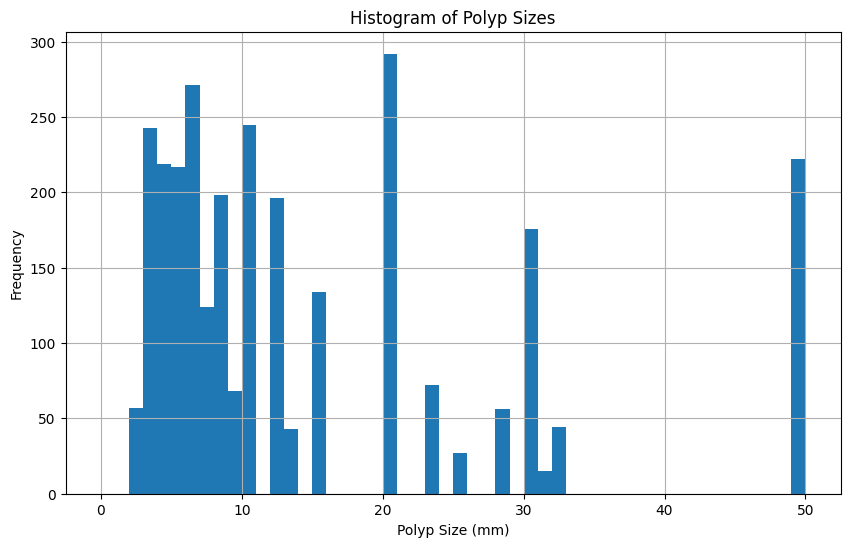

POLYP SIZE (mm)
20    292
6     271
10    245
3     243
50    222
4     219
5     217
8     198
12    196
30    176
15    134
7     124
23     72
9      68
2      57
28     56
32     44
13     43
25     27
31     15
Name: count, dtype: int64

In [23]:
# Calculating the distribution of polyp sizes
polyp_size_distribution = extended_piccolo_df['POLYP SIZE (mm)'].value_counts()

# Plotting the histogram of polyp sizes
plt.figure(figsize=(10, 6))
extended_piccolo_df['POLYP SIZE (mm)'].hist(bins=range(0, int(extended_piccolo_df['POLYP SIZE (mm)'].max()) + 1, 1))
plt.title('Histogram of Polyp Sizes')
plt.xlabel('Polyp Size (mm)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

polyp_size_distribution

In [ ]:
# Descriptive statistics and Box plot

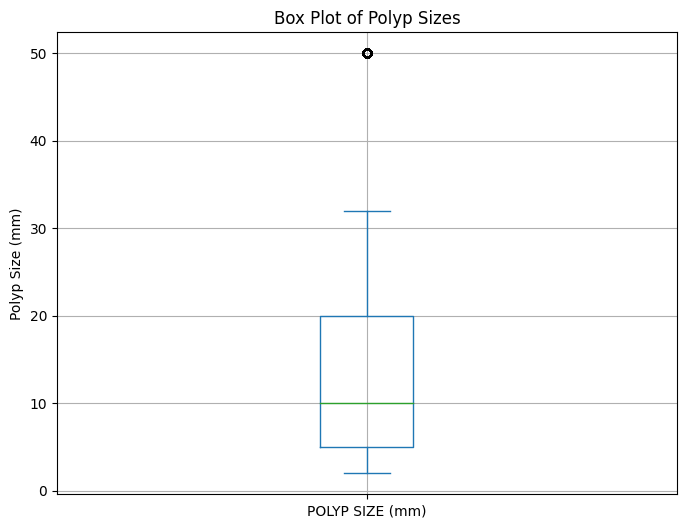

count    2919.000000
mean       14.682083
std        13.021901
min         2.000000
25%         5.000000
50%        10.000000
75%        20.000000
max        50.000000
Name: POLYP SIZE (mm), dtype: float64

In [25]:
# Calculating descriptive statistics for polyp sizes
polyp_size_descriptive_stats = extended_piccolo_df['POLYP SIZE (mm)'].describe()

# Plotting the box plot for polyp sizes
plt.figure(figsize=(8, 6))
extended_piccolo_df['POLYP SIZE (mm)'].plot(kind='box')
plt.title('Box Plot of Polyp Sizes')
plt.ylabel('Polyp Size (mm)')
plt.grid(True)
plt.show()

polyp_size_descriptive_stats

In [ ]:
# Distribution of polyp sizes based on the different ranges considered by POLAR's authors: Diminutive Polyps (1-5 mm), Small Polyps (6-9 mm), Larger Polyps (>=10 mm)

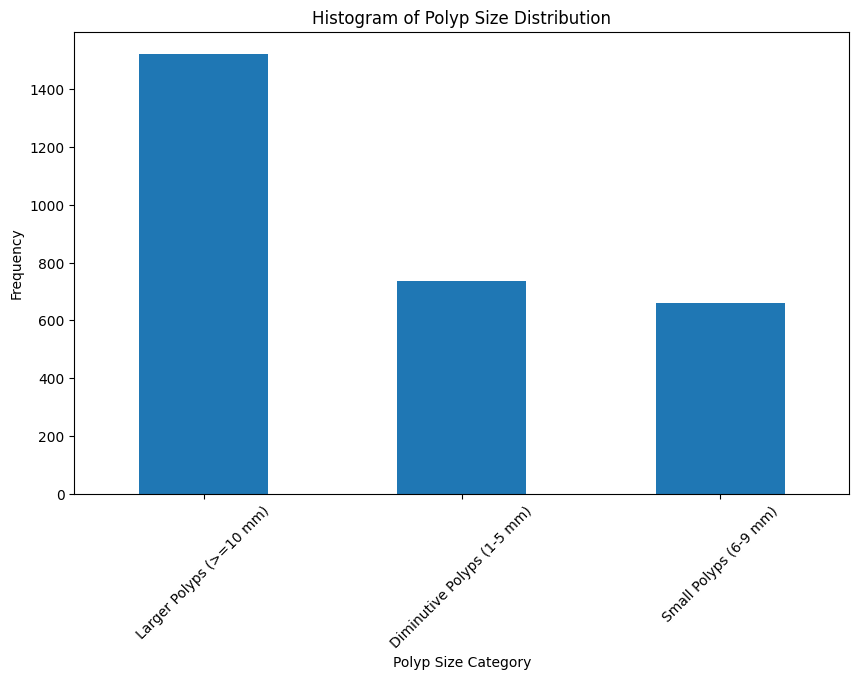

POLYP SIZE (mm)
Larger Polyps (>=10 mm)       1522
Diminutive Polyps (1-5 mm)     736
Small Polyps (6-9 mm)          661
Name: count, dtype: int64

In [30]:
def classify_polyp(size):
    if size <= 5:
        return 'Diminutive Polyps (1-5 mm)'
    elif size <= 9:
        return 'Small Polyps (6-9 mm)'
    else:
        return 'Larger Polyps (>=10 mm)'
    
polyp_classification = extended_piccolo_df['POLYP SIZE (mm)'].apply(classify_polyp)
polyp_size_distribution = polyp_classification.value_counts()


# Plotting the histogram
plt.figure(figsize=(10, 6))
polyp_size_distribution.plot(kind='bar')
plt.title('Histogram of Polyp Size Distribution')
plt.xlabel('Polyp Size Category')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

polyp_size_distribution

In [ ]:
# Distribution by morphology (defined using the values considered by the Paris classification)

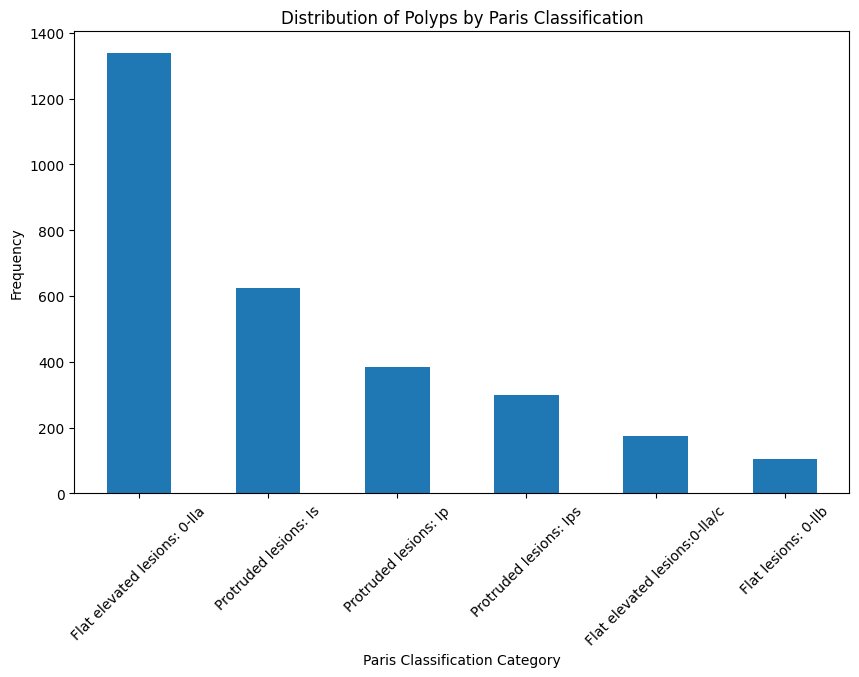

PARIS CLASSIFICATION
Flat elevated lesions: 0-lla     1337
Protruded lesions: Is             623
Protruded lesions: Ip             383
Protruded lesions: Ips            298
Flat elevated lesions:0-lla/c     174
Flat lesions: 0-llb               104
Name: count, dtype: int64

In [31]:
# Calculating the distribution of polyps by Paris classification
paris_classification_distribution = extended_piccolo_df['PARIS CLASSIFICATION'].value_counts()

# Plotting the histogram
plt.figure(figsize=(10, 6))
paris_classification_distribution.plot(kind='bar')
plt.title('Distribution of Polyps by Paris Classification')
plt.xlabel('Paris Classification Category')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

paris_classification_distribution

In [ ]:
# Polyp localization analysis based on bounding boxes. Descriptive statistics

In [32]:
def extract_coordinates(bbox_str):
    coordinates = []
    if bbox_str:
        boxes = bbox_str.split(' ')
        for box in boxes:
            xmin, ymin, xmax, ymax = [int(coord) for coord in box.split(',')]
            coordinates.append((xmin, ymin, xmax, ymax))
    return coordinates

# Apply the function to the DataFrame
bbox_data = extended_piccolo_df['BOUNDING BOX'].apply(extract_coordinates)

# Initialize lists to store individual coordinates
min_x, min_y, max_x, max_y = [], [], [], []

# Extract individual coordinates
for row in bbox_data:
    for (xmin, ymin, xmax, ymax) in row:
        min_x.append(xmin)
        min_y.append(ymin)
        max_x.append(xmax)
        max_y.append(ymax)

# Calculate descriptive statistics for each set of coordinates
stats = {
    'min_x': pd.Series(min_x).describe(),
    'min_y': pd.Series(min_y).describe(),
    'max_x': pd.Series(max_x).describe(),
    'max_y': pd.Series(max_y).describe()
}

stats

{'min_x': count    3002.000000
 mean      427.050966
 std       244.763577
 min       136.000000
 25%       270.000000
 50%       361.000000
 75%       538.000000
 max      1746.000000
 dtype: float64,
 'min_y': count    3002.000000
 mean      166.832445
 std       146.159899
 min         0.000000
 25%        40.000000
 50%       146.500000
 75%       259.000000
 max      1071.000000
 dtype: float64,
 'max_x': count    3002.000000
 mean      905.387075
 std       482.714515
 min       198.000000
 25%       521.000000
 50%       683.000000
 75%      1434.750000
 max      1803.000000
 dtype: float64,
 'max_y': count    3002.000000
 mean      588.328448
 std       303.195228
 min        12.000000
 25%       364.000000
 50%       479.000000
 75%       911.250000
 max      1079.000000
 dtype: float64}